# Simple Linear Regression (Contains only one feature)

In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
df = pd.read_csv("experience_salary.csv")

In [3]:
df.head()

,experience,salary
0,0.00,26371
1,0.04,20581
2,0.08,28898
3,0.12,30014
4,0.16,17262


In [4]:
df.tail()

,experience,salary
495,19.84,158168
496,19.88,145977
497,19.92,152969
498,19.96,145781
499,20.00,148272


In [5]:
df.shape

(500, 2)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   experience  500 non-null    float64
 1   salary      500 non-null    int64  
dtypes: float64(1), int64(1)
memory usage: 7.9 KB


In [7]:
# selct input feature
X = df[["experience"]]
y = df["salary"]

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 400
Testing records: 100


In [9]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [10]:
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 6534.5168528226095
Intercept: 24569.792369461


In [11]:
# actual y

y_pred = model.predict(X_test)
print(y_test.values)

[120773  46255 124928  73336  47893 130804 114201  61063  46576 141644
  23506  70559 130243  41502 127634 127325 158168  42453 107624 122324
 157539 154565 100107 118800  42877 141350 152969  74001  57159 112162
 147221 109515 138778  64555  28898 107192 125719  37496  77945  44051
 117834  48870 150586  80107  29935  45774  26371  31366 134006  36233
  39620  70566  52933 125144  81857  36454  68354  33642  68921  48136
 152308  94301 112527 153445  44189  38088 144064  40905  82223 127108
 114134 115207  92158  99417 104447 103922  95059  42115 144258 144078
  64878  44729 144130  67762 107769  51441  77771 131574 114130 102785
 130151 146686 123808 117602 139421 118060  45292  47646 136164  25041]


In [12]:
# predicted y
print(y_pred)

[119124.2512298   43715.92674823 122522.19999327  65149.14202549
  51818.72764573 127749.81347553 123306.34201561  57046.34112799
  42409.02337767 142452.47639438  26922.21843648  75408.33348442
 130886.38156488  46591.11416347 121738.05797093 126181.52943085
 154214.60672946  32411.21259285 107362.12089472 131409.14291311
 152907.7033589  153169.08403301  97887.07145813 117817.34785924
  44500.06877057 145327.66380962 154737.36807769  79851.80494434
  51034.58562339 112066.97302876 148986.9932472  112589.73437698
 139838.66965325  69853.99415952  25092.55371769 111805.59235464
 131670.52358722  42931.78472589  79329.04359611  41102.1200071
 125136.0067344   48943.54023049 151600.79998833  72990.56224888
  33195.35461519  44761.44944468  24569.79236946  27444.9797847
 133238.8076319   30320.16719994  43454.54607412  72206.42022654
  58876.00584678 131931.90426134  75146.95281031  38945.72944567
  63319.4773067   29274.64450349  78022.14022555  45022.8301188
 153953.22605535  93182.2193

In [13]:
#errors => actual - predicted
errors = y_test.values - y_pred
print(errors)

[ 1.64874877e+03  2.53907325e+03  2.40580001e+03  8.18685797e+03
 -3.92572765e+03  3.05418652e+03 -9.10534202e+03  4.01665887e+03
  4.16697662e+03 -8.08476394e+02 -3.41621844e+03 -4.84933348e+03
 -6.43381565e+02 -5.08911416e+03  5.89594203e+03  1.14347057e+03
  3.95339327e+03  1.00417874e+04  2.61879105e+02 -9.08514291e+03
  4.63129664e+03  1.39591597e+03  2.21992854e+03  9.82652141e+02
 -1.62306877e+03 -3.97766381e+03 -1.76836808e+03 -5.85080494e+03
  6.12441438e+03  9.50269712e+01 -1.76599325e+03 -3.07473438e+03
 -1.06066965e+03 -5.29899416e+03  3.80544628e+03 -4.61359235e+03
 -5.95152359e+03 -5.43578473e+03 -1.38404360e+03  2.94887999e+03
 -7.30200673e+03 -7.35402305e+01 -1.01479999e+03  7.11643775e+03
 -3.26035462e+03  1.01255056e+03  1.80120763e+03  3.92102022e+03
  7.67192368e+02  5.91283280e+03 -3.83454607e+03 -1.64042023e+03
 -5.94300585e+03 -6.78790426e+03  6.71004719e+03 -2.49172945e+03
  5.03452269e+03  4.36735550e+03 -9.10114023e+03  3.11316988e+03
 -1.64522606e+03  1.11878

In [14]:
# need to convert neg to pos so for that use mse
print("Mean squared error:", mean_squared_error(y_test, y_pred))

Mean squared error: 17241668.87725972


In [15]:
print("R2 Score:", r2_score(y_test, y_pred))

R2 Score: 0.9898349943166155


In [16]:
# check values are nearest or far away with visualization
import matplotlib.pyplot as plt

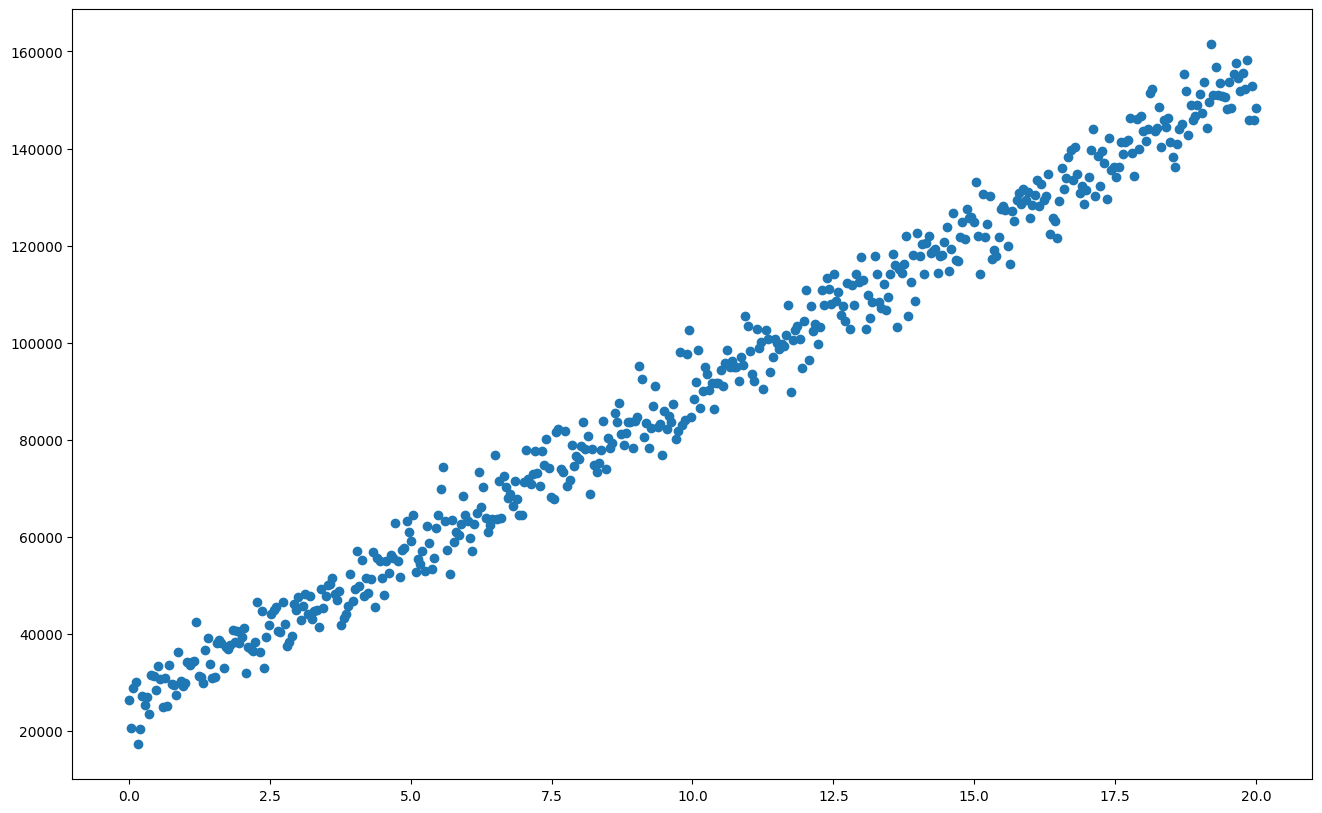

In [17]:
plt.figure(figsize = (16, 10))
plt.scatter(df["experience"], df["salary"], label = "Actual data")

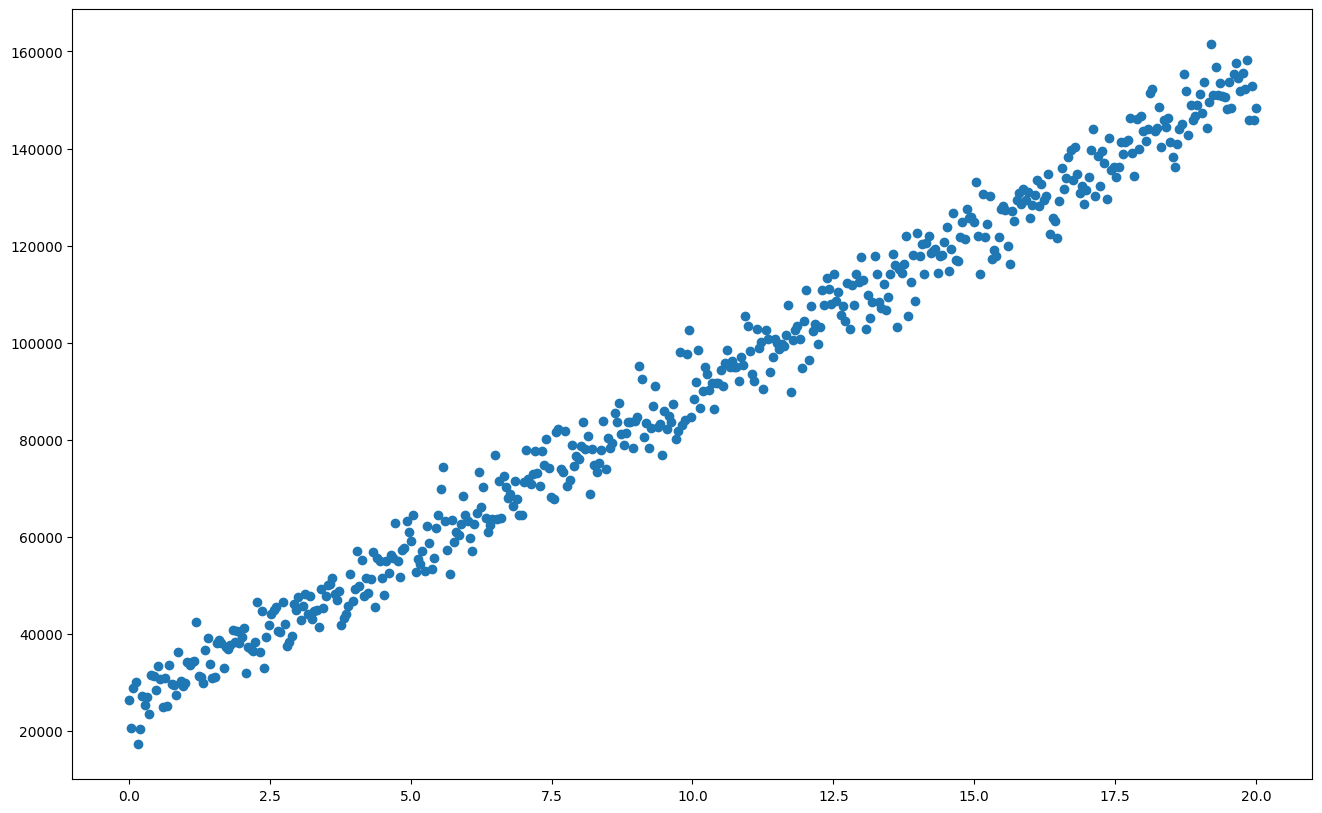

In [18]:
plt.figure(figsize = (16, 10))
plt.scatter(df["experience"], df["salary"], label = "Actual data")

X_line = pd.DataFrame({
    "experience": sorted(df["experience"])
})

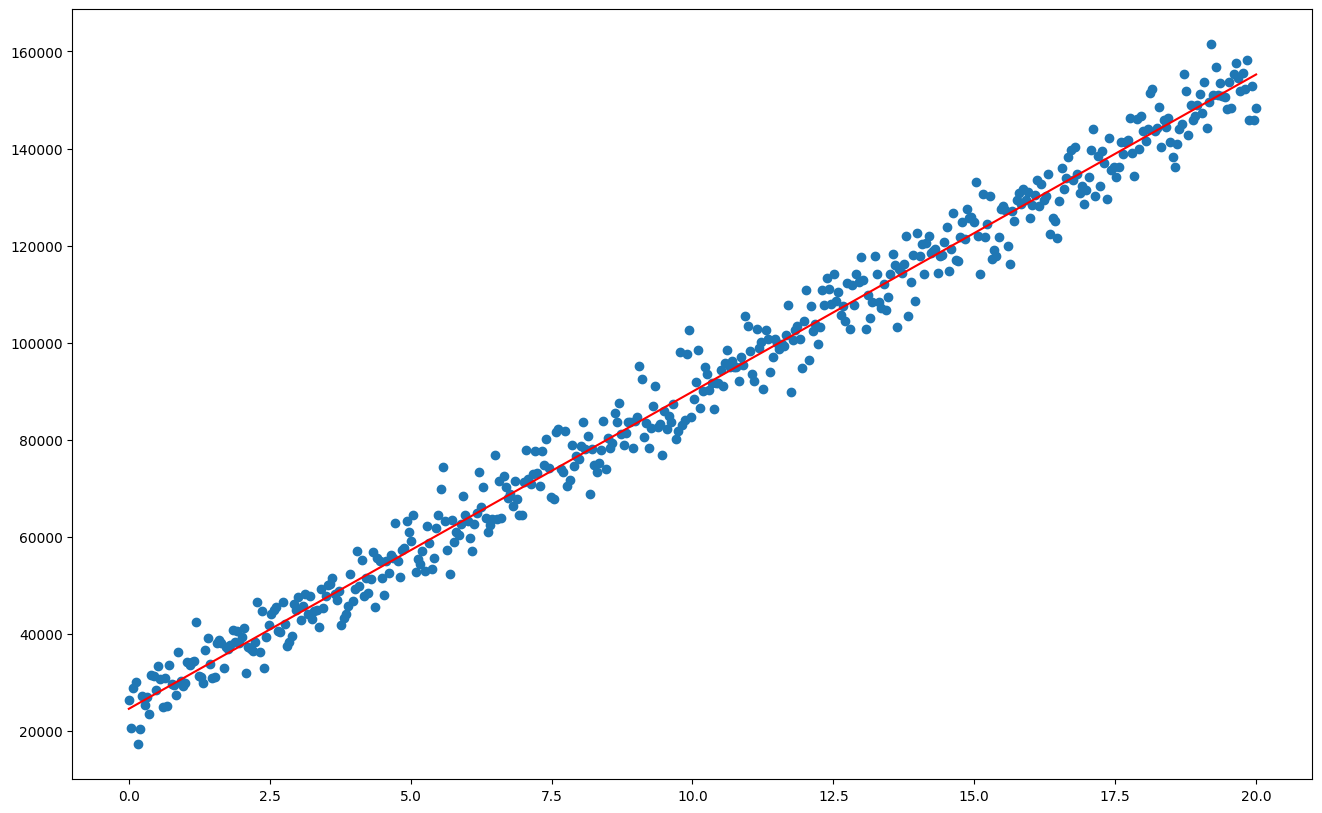

In [19]:
plt.figure(figsize = (16, 10))
plt.scatter(df["experience"], df["salary"], label = "Actual data")

X_line = pd.DataFrame({
    "experience": sorted(df["experience"])
})

y_line = model.predict(X_line)

plt.plot(
    X_line["experience"],
    y_line,
    color = 'red',
    label = "Regression Line"
)

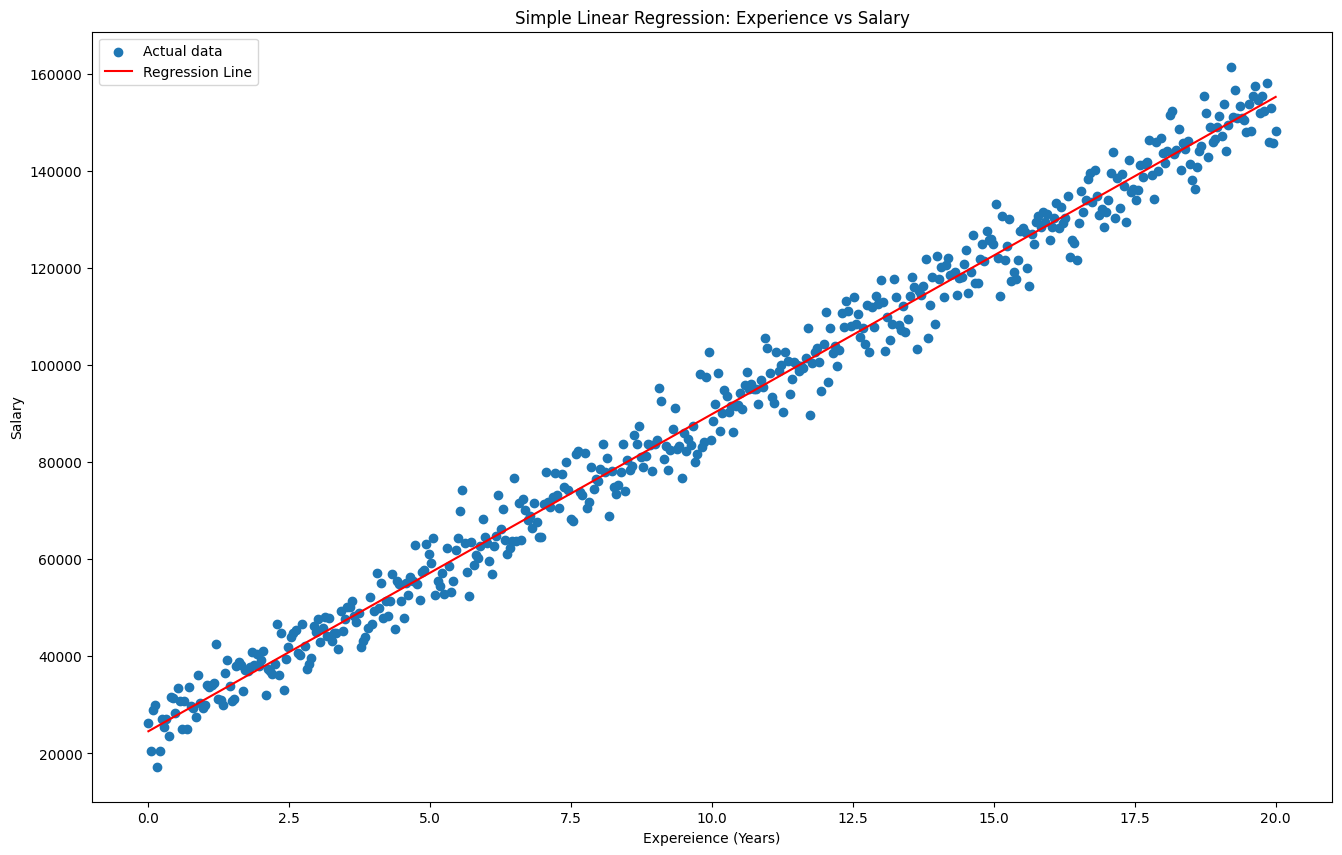

In [20]:
plt.figure(figsize = (16, 10))
plt.scatter(df["experience"], df["salary"], label = "Actual data")

X_line = pd.DataFrame({
    "experience": sorted(df["experience"])
})

y_line = model.predict(X_line)

plt.plot(
    X_line["experience"],
    y_line,
    color = 'red',
    label = "Regression Line"
)

plt.xlabel("Expereience (Years)")
plt.ylabel("Salary")
plt.title("Simple Linear Regression: Experience vs Salary")
plt.legend()
plt.show()

In [21]:
new_experience = pd.DataFrame({"experience": [1.0]})
predicted_salary = model.predict(new_experience)

print("predicted Salary for 1 year Experience:", predicted_salary[0])

predicted Salary for 1 year Experience: 31104.30922228361


# Multiple Linear Regression (Contains multiple features)

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder

In [23]:
df = pd.read_csv("Student_Performance.csv")

In [24]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [25]:
df.shape

(10000, 6)

In [26]:
# check missing values
df.isnull().sum()

Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

In [27]:
df = df.dropna().copy()

In [28]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [29]:
df.shape

(10000, 6)

In [30]:
# we have categorical column , convert categorical data into numerical data

# label encode => numerical data => output 0, 1

le = LabelEncoder()
le

LabelEncoder()

In [31]:
df["Extracurricualr Activities"] = le.fit_transform(
    df["Extracurricular Activities"]
)

# yes --> 1, No --> 0
print(df.head())

   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  \
0                                 1               91.0   
1                                 2               65.0   
2                                 2               45.0   
3                                 2               36.0   
4                                 5               66.0   

   Extracurricualr Activities  
0                           1  
1                           0  
2                           1  
3                           1  
4                           

In [32]:
# split , drop the target column

X = df.drop("Performance Index", axis = 1)
y = df["Performance Index"]

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 8000
Testing records: 2000


In [38]:
model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [39]:
print("Intercept:", model.intercept_)

for feature, coefficient in zip(X.columns, model.coef_):
    print(f"{feature}: {coefficient:.4f}")

Intercept: -33.92194621555608
Hours Studied: 2.8525
Previous Scores: 1.0170
Sleep Hours: 0.4769
Sample Question Papers Practiced: 0.1918
Extracurricualr Activities: 0.3043
Extracurricular Activities_Yes: 0.3043


In [40]:
equation = f"Performance Index = {model.intercept_:.4f}"
equation

'Performance Index = -33.9219'

In [41]:
for feature, coefficient in zip(X.columns, model.coef_):
    equation += f" + ({coefficient:.4f} * {feature})"

print(equation)

Performance Index = -33.9219 + (2.8525 * Hours Studied) + (1.0170 * Previous Scores) + (0.4769 * Sleep Hours) + (0.1918 * Sample Question Papers Practiced) + (0.3043 * Extracurricualr Activities) + (0.3043 * Extracurricular Activities_Yes)


In [42]:
y_pred = model.predict(X_test)

print(y_test.head(10).values)
print(y_pred[:10])

[51. 20. 46. 28. 41. 59. 48. 87. 37. 73.]
[54.71185392 22.61551294 47.90314471 31.28976748 43.00457042 59.07125171
 45.90347516 86.45911791 37.70014037 72.05592481]


In [43]:
errors = y_test.values - y_pred
print(errors[:10])

[-3.71185392 -2.61551294 -1.90314471 -3.28976748 -2.00457042 -0.07125171
  2.09652484  0.54088209 -0.70014037  0.94407519]


In [44]:
print("Mean squared error:", mean_squared_error(y_test, y_pred))

Mean squared error: 4.082628398521854


In [45]:
print("R2 score:", r2_score(y_test, y_pred))
      

R2 score: 0.9889832909573145


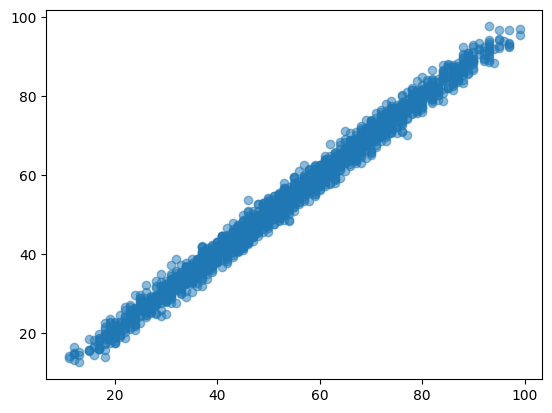

In [46]:
plt.scatter(y_test, y_pred, alpha = 0.5)

In [47]:
df.columns

Index(['Hours Studied', 'Previous Scores', 'Extracurricular Activities',
       'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index',
       'Extracurricualr Activities'],
      dtype='object')

In [51]:
new_student = pd.DataFrame({
    'Hours Studied':[7],
    'Previous Scores': [80],
    'Extracurricular Activities': [1],
    'Sleep Hours': [8],
    'Sample Question Papers Practiced':[5],
    'Extracurricular Activities_Yes': [1]
})

# predicted_performance = model.predict(new_student)
# print(predicted_performance)

# Ensure columns are in the exact same order as X_train
new_student = new_student[X_train.columns]

predicted_performance = model.predict(new_student)
print(predicted_performance[0])

KeyError: "['Extracurricualr Activities'] not in index"

# VIF

In [52]:
pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.3
[notice] To update, run: C:\Users\bhuva\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [2]:
df = pd.DataFrame({
    "Hours_Studies":[2,3,4,5,6,7,8,9,10,11],
    "Practice_Papers":[1,2,4,4,6,7,7,9,10,11],
    "Sleep_Hours":[8,7,6,8,7,9,6,8,7,6],
    "marks":[35,40,50,55,62,70,73,82,88,92]
})

df

,Hours_Studies,Practice_Papers,Sleep_Hours,marks
0,2,1,8,35
1,3,2,7,40
2,4,4,6,50
3,5,4,8,55
4,6,6,7,62
5,7,7,9,70
6,8,7,6,73
7,9,9,8,82
8,10,10,7,88
9,11,11,6,92


In [4]:
X = df[["Hours_Studies", "Practice_Papers", "Sleep_Hours"]]

X = add_constant(X)
X

,const,Hours_Studies,Practice_Papers,Sleep_Hours
0,1.0,2,1,8
1,1.0,3,2,7
2,1.0,4,4,6
3,1.0,5,4,8
4,1.0,6,6,7
5,1.0,7,7,9
6,1.0,8,7,6
7,1.0,9,9,8
8,1.0,10,10,7
9,1.0,11,11,6


In [5]:
vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns[1:]
vif_data

,Feature
0,Hours_Studies
1,Practice_Papers
2,Sleep_Hours


In [6]:
vif_data["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(1, X.shape[1])
]

vif_data.round(2)

,Feature,VIF
0,Hours_Studies,63.11
1,Practice_Papers,62.74
2,Sleep_Hours,1.06
